# Mini-Spaun, part 1: Semantic Pointers in spiking neurons
In this notebook (and others) I will attempt to recreate a mini-spaun model (Eliasmith et al., 2012). I will be creating it from scratch using brian2 and torchhd. This notebook will end on how one population of spiking neurons can represent high-dimensional vectors.

My goal is to understand the model, find its applications on the way and research gaps. I aim to create a solid foundation of future research on the topic of large-scale brain models to elucidate complex systems and diseases in/of the brain.

To be transparant of my AI usage, I will be using Claude (Anthropic) to help me understand the workings of Spaun and write the code. While I believe we should reduce the use of LLMs such that we do not lose our creativity and the ability to develop skill, I first need to get a grasp on how this model works before I can get creative. I will attempt to use AI as a guide such that I can become independent in writing my future ideas on paper and in software.

## Roadmap
1. Symbols without neurons (torchhd): build a vocabulary of semantic pointers. Bind, combine and retrieve them.
2. One population, one number (brian2): make a group of leaky integrate-and-fire (LIF) neurons with varied tuning curves represent a single value. Then recover (“decode”) that value from their spikes.
3. Populations representing vectors: generalise step 2 to vectors. This is Georgopoulos’ population vector, but in many dimensions.
4. Connections that compute: choose synaptic weights so that population B represents some function of population A.
5. Working memory: add a recurrent connection so a population holds its value after the input disappears, like the PFC delay cells in Goldman-Rakic’s work.
6. Action selection with basal ganglia: the direct and indirect pathways, and GPi’s tonic inhibition of thalamus being released for the winning action. Your neurology background on Parkinson’s will make this part feel familiar.
7. One toy task end-to-end: for example, show a sequence of symbols, store it in working memory, and have basal ganglia decide when to recall it.

In [1]:
import torchhd 
import pandas as pd
import torch

# 1. Semantic pointers in torchhd

In [2]:
D = 512

# Vocabulary
COLOR, SHAPE, RED, BLUE, CIRCLE, SQUARE = torchhd.random(6, D, 'HRR')

# Binding & Bundling
## RedxColor
RedxColor = torchhd.bind(RED, COLOR)
CirclexShape = torchhd.bind(CIRCLE, SHAPE)
## Circle_RedxColor
Circle_RedxColor = torchhd.bundle(RedxColor, CirclexShape)

# Unbind (inverse)
Circle_Red = torchhd.bind(Circle_RedxColor, torchhd.inverse(COLOR)) # Takes out color, so we end up with a vector close to RED (the CirclexShape part is scrambled now)

# Cosine Similarity
print(f"Circle_Red v. COLOR: {torchhd.cosine_similarity(Circle_Red, COLOR)}")
print(f"Circle_Red v. SHAPE: {torchhd.cosine_similarity(Circle_Red, SHAPE)}")
print(f"Circle_Red v. RED: {torchhd.cosine_similarity(Circle_Red, RED)}")
print(f"Circle_Red v. BLUE: {torchhd.cosine_similarity(Circle_Red, BLUE)}")
print(f"Circle_Red v. CIRCLE: {torchhd.cosine_similarity(Circle_Red, CIRCLE)}")
print(f"Circle_Red v. SQUARE: {torchhd.cosine_similarity(Circle_Red, SQUARE)}")
print(f"Circle_Red v. CirclexShape: {torchhd.cosine_similarity(Circle_Red, CirclexShape)}")



Circle_Red v. COLOR: HRRTensor(-0.0299)
Circle_Red v. SHAPE: HRRTensor(-0.0032)
Circle_Red v. RED: HRRTensor(0.5912)
Circle_Red v. BLUE: HRRTensor(0.0476)
Circle_Red v. CIRCLE: HRRTensor(0.0111)
Circle_Red v. SQUARE: HRRTensor(0.0340)
Circle_Red v. CirclexShape: HRRTensor(0.0196)


Here, I created simple representations of a small vocabulary (unefficiently written in python :/). I also showed the effect of unbinding, which looks like this:
$$
COLOR^{-1} \otimes [(RED \otimes COLOR) \oplus (CIRCLE \otimes SHAPE)] \\
= (RED) \oplus (CIRCLE \otimes SHAPE  \otimes COLOR^{-1})
$$

The outcome will be similar to RED, because it is a bundle of RED and another term. It will not be similar anymore to CIRCLE or SHAPE, because the inverse of COLOR scrambles its meaning.

As we can see, the similarity to RED is not 100%. This is normal, because there is noise coming from the scrambled term.
Spaun wants these scores to be exact, and allows for attractors to complete a degraded pattern. This way, it can confidently say which vector, which word represents.

The more neurons, the less noise. Since dimensionality represents the amount of neurons, we can show this.

In [3]:
import numpy as np
import pandas as pd
from collections import Counter

dims = [16, 32, 64, 128, 512, 2048]
vocab = ["COLOR", "SHAPE", "RED", "BLUE", "CIRCLE", "SQUARE"]
n_runs = 50
rows = []

for D in dims:
    sim_red, sim_other, margins, best_names = [], [], [], []

    for run in range(n_runs):
        hvs = torchhd.random(len(vocab), D, vsa="HRR")
        dvocab = dict(zip(vocab, hvs))

        RedxColor = torchhd.bind(dvocab["RED"], dvocab["COLOR"])
        CirclexShape = torchhd.bind(dvocab["CIRCLE"], dvocab["SHAPE"])
        record = torchhd.bundle(RedxColor, CirclexShape)
        query = torchhd.bind(record, torchhd.inverse(dvocab["COLOR"]))

        sims = {name: torchhd.cosine_similarity(query, hv).item()
                for name, hv in dvocab.items()}
        distractors = {n: s for n, s in sims.items() if n != "RED"}
        best = max(distractors, key=distractors.get)

        sim_red.append(sims["RED"])
        sim_other.append(distractors[best])
        margins.append(sims["RED"] - distractors[best])
        best_names.append(best)

    rows.append({
        "D": D,
        "RED_mean": np.mean(sim_red),
        "RED_sd": np.std(sim_red),
        "runner_up": Counter(best_names).most_common(1)[0][0],
        "runner_up_mean": np.mean(sim_other),
        "runner_up_sd": np.std(sim_other),
        "diff_mean": np.mean(margins),
        "diff_sd": np.std(margins),
    })

results = pd.DataFrame(rows)
print(results.round(3).to_string(index=False))

   D  RED_mean  RED_sd runner_up  runner_up_mean  runner_up_sd  diff_mean  diff_sd
  16     0.578   0.135     COLOR           0.376         0.178      0.202    0.253
  32     0.574   0.113     COLOR           0.241         0.152      0.333    0.184
  64     0.583   0.069     COLOR           0.195         0.104      0.388    0.126
 128     0.578   0.057     COLOR           0.113         0.075      0.465    0.095
 512     0.582   0.026    CIRCLE           0.054         0.033      0.527    0.042
2048     0.576   0.013     COLOR           0.031         0.019      0.546    0.023


Here, we see that the score of RED stays around the same. But if we look at the runner up word, we can see that its score decreases. This means that the higher the dimension, the lower the noise will be on the other words.

What happens when we increase the number of pairs within one embedding?

In [4]:
D = 512
vocab = ["COLOR", "RED", "BLUE", 
         "SHAPE", "CIRCLE", "SQUARE", 
         "SIZE", "BIG", "SMALL",
         "POSITION", "LEFT", "RIGHT",
         "MATERIAL", "HARD", "SOFT"]
n_runs = 50
rows = []


sim_red, sim_other, margins, best_names = [], [], [], []

for run in range(n_runs):
    hvs = torchhd.random(len(vocab), D, vsa="HRR")
    dvocab = dict(zip(vocab, hvs))

    RedxColor = torchhd.bind(dvocab["RED"], dvocab["COLOR"])
    CirclexShape = torchhd.bind(dvocab["CIRCLE"], dvocab["SHAPE"])
    SizexBig = torchhd.bind(dvocab["SIZE"], dvocab["BIG"])
    MaterialxHard = torchhd.bind(dvocab["MATERIAL"], dvocab["HARD"])

    record1 = torchhd.bundle(RedxColor, CirclexShape)
    record2 = torchhd.bundle(record1, SizexBig)
    record3 = torchhd.bundle(record2, MaterialxHard)
    query = torchhd.bind(record3, torchhd.inverse(dvocab["COLOR"]))

    sims = {name: torchhd.cosine_similarity(query, hv).item()
                for name, hv in dvocab.items()}
    distractors = {n: s for n, s in sims.items() if n != "RED"}
    best = max(distractors, key=distractors.get)

    sim_red.append(sims["RED"])
    sim_other.append(distractors[best])
    margins.append(sims["RED"] - distractors[best])
    best_names.append(best)

rows.append({
    "D": D,
    "RED_mean": np.mean(sim_red),
    "RED_sd": np.std(sim_red),
    "runner_up": Counter(best_names).most_common(1)[0][0],
    "runner_up_mean": np.mean(sim_other),
    "runner_up_sd": np.std(sim_other),
    "diff_mean": np.mean(margins),
    "diff_sd": np.std(margins),
})

results = pd.DataFrame(rows)
print(results.round(3).to_string(index=False))

  D  RED_mean  RED_sd runner_up  runner_up_mean  runner_up_sd  diff_mean  diff_sd
512     0.448   0.036    CIRCLE           0.086         0.029      0.362    0.053


The similarity shrinks as the number of pairs grow. This is a link to the limit of the working memory.

## Step 2: One population, one number
### x to Spike
Each neuron gets three properties:
- An encoder, +1 or -1: This says whether it fires more for positive or negative x, like ON & OFF cells.
- A gain: How steeply its firing rate rises with input.
- A bias: A constant background current.

The input current is: $\text{gain} \times \text{encoder} \times \text{x} + \text{bias}$.

Here, I will simulate a NeuronGroup in which each neuron has their own random parameters with one chosen value x. 'x' is the quantity the population is representing, a number between -1 & +1 that we choose. In here it does not represent anything yet, but it can represent any 1D variable a brain area might encode: eye position, frequency of a vibration on fingertip, ... It describes the simplest "thought" a population can hold, later this is scaled up to semantic pointers (Hypervectors).

I will record the population of neurons and count each neuron's spikes for one second.

In [5]:
import brian2 as b2
import numpy as np

b2.start_scope()

tau = 20*b2.ms
intercept = np.random.uniform(-1, 1, size=50) # value of (encoder * x) at which the neuron starts firing; sets its threshold in stimulus space
encoder = np.random.choice([-1,1], size=50) # how steeply the firing rate rises once above the intercept; the slope of the f–I curve
gain = np.random.uniform(1, 5, size=50)


eq = """
dv/dt = (I - v)/tau : 1 (unless refractory)
I = gain * (encoder * x - intercept) + 1 : 1
gain : 1 (constant)
encoder : 1 (constant)
intercept : 1 (constant)
x : 1 (shared)
"""

G = b2.NeuronGroup(50, eq, threshold='v>1', reset = 'v=0', refractory=2*b2.ms)

G.intercept = intercept
G.encoder = encoder
G.gain = gain

spmon = b2.SpikeMonitor(G) # Records the spikes

b2.store()

xs = np.linspace(-1, 1, 20)
duration = 1*b2.second
firing_rates = []

for x in xs:
    b2.restore()
    G.x = x
    b2.run(duration)
    firing_rates.append((spmon.count/duration)/b2.Hz)

firing_rates = np.array(firing_rates)
print(firing_rates.shape)

INFO       Cache size for target 'cython': 2549 MB.
You can call clear_cache('cython') to delete all files from the cache or manually delete files in the 'C:\Users\wille\.cython\brian_extensions' directory. [brian2]
WARNING    'x' is an internal variable of group 'neurongroup', but also exists in the run namespace with the value np.float64(-1.0). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'intercept' is an internal variable of group 'neurongroup', but also exists in the run namespace with the value array([ 0.15055076,  0.60444425,  0.90124262, ..., -0.8884244 ,
       -0.81126804, -0.6017102 ], shape=(50,)). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'encoder' is an internal variable of group 'neurongroup', but also exists in the run namespace with the value array([ 1,  1, -1, ..., -1,  1,  1], shape=(50,)). The internal variable will be used. [brian2.groups.group.Gro

(20, 50)


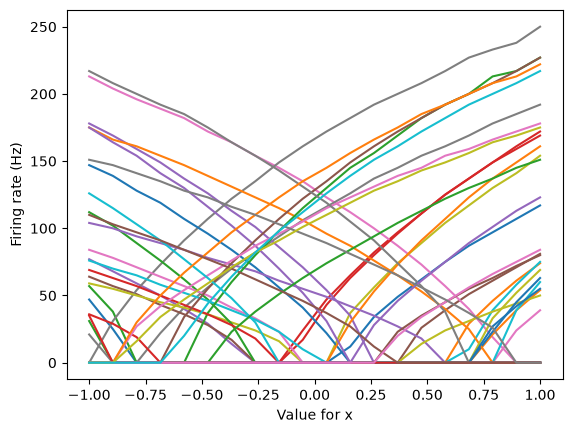

In [6]:
import matplotlib.pyplot as plt

plt.plot(xs, firing_rates)
plt.xlabel("Value for x")
plt.ylabel("Firing rate (Hz)")
plt.show()

Each line is a neuron, and it shows their tuning curves.
- Two families with opposite directions: 
  - Right (+1): Fire more as x becomes more positive
  - Left (-1): Fire less as x becomes more positive
- Each neuron is silent up to a point, then it start firing. This is the intercept.
- The steepness comes from the gain.

These are monotonic, rectified tuning curves with heterogeneous thresholds and slopes. An example of this kind of population: **Oculomotor integrator neurons** in the brainstem, whose firing rate rises with eye position, with some preferring left and some right, each with a different recruitment threshold.


### Spike to x (decoding)
During decoding we estimate x from the firing rates alone. This is the second part of NEF. The estimate is a weighted sum of the neurons' firing rates. When x is positive, the encoder +1 neurons fire a lot. So, positive decoders turn that activity into a positive estimate. Negative decoders pull the estimate down.

(50,)
(20,)


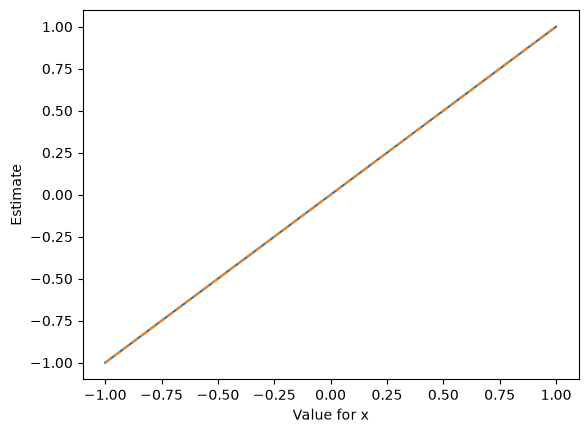

In [7]:
# We use the least-squares solution (on a linear matrix, firing_rates)
decoder = np.linalg.lstsq(firing_rates, xs, rcond=None)[0] # The first return is the decoder vector
print(decoder.shape) # (50,) -> 1 weight per neuron

# Compute estimate
estimate = firing_rates @ decoder # @ is for matrix multiplication
print(estimate.shape)

plt.plot(xs, estimate)
plt.plot(xs, xs, linestyle='dashed')
plt.xlabel("Value for x")
plt.ylabel("Estimate")
plt.show()

We can see that the fit worked, but this does not tell us how well the population x represents.

To test the latter, we need to test the (old) decoders on new x-values (100 in total now).

In [8]:
xs_100 = np.linspace(-1, 1, 100) # Increased amount of x-values
duration_05 = 0.5*b2.second
firing_rates_100 = []

for x in xs_100:
    b2.restore()
    G.x = x
    b2.run(duration_05)
    firing_rates_100.append((spmon.count/duration_05)/b2.Hz)

firing_rates_100 = np.array(firing_rates_100)
print(firing_rates_100.shape)

WARNING    'x' is an internal variable of group 'neurongroup', but also exists in the run namespace with the value np.float64(-0.9797979797979798). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'x' is an internal variable of group 'neurongroup', but also exists in the run namespace with the value np.float64(-0.9595959595959596). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'x' is an internal variable of group 'neurongroup', but also exists in the run namespace with the value np.float64(-0.9393939393939394). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'x' is an internal variable of group 'neurongroup', but also exists in the run namespace with the value np.float64(-0.9191919191919192). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'x' is an internal variable o

(100, 50)


(100,)


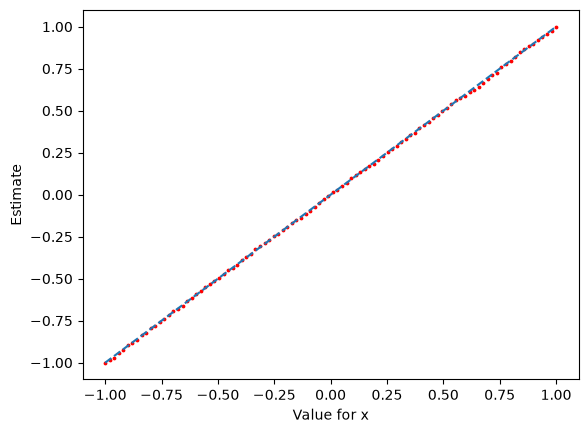

In [9]:
# Compute estimate with old decoder!
estimate = firing_rates_100 @ decoder # @ is for matrix multiplication
print(estimate.shape)

# Plot
plt.scatter(xs_100, estimate, s=3, c="Red")
plt.plot(xs_100, xs_100, linestyle='dashed')
plt.xlabel("Value for x")
plt.ylabel("Estimate")
plt.show()

Here, we see that the estimates are still very accurate. From firing rates, we can recover x almost perfectly while we are using new x-values and decoders created from old x-values.
The small deviations come from kinks in tuning curves. However, this is too perfect ofcourse. The LIF neurons are deterministic, so we need to add trial-to-trial noise. 

(100,)


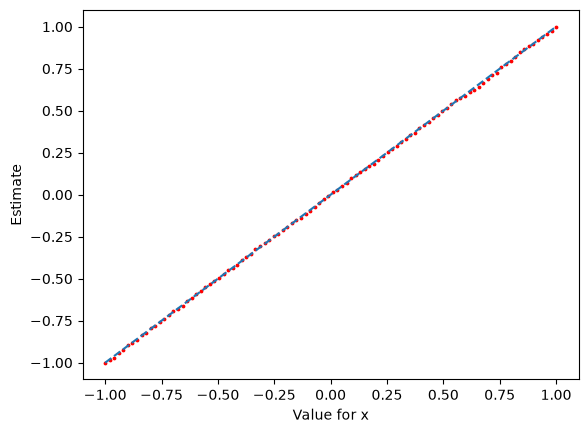

In [10]:
# Copy firing_rates_100
noisy_frs = firing_rates_100 + np.random.normal(0, 10, firing_rates_100.shape)

# Compute estimate with old decoder!
estimate_noisy = noisy_frs @ decoder # @ is for matrix multiplication
print(estimate.shape)

plt.scatter(xs_100, estimate, s=3, c="Red")
plt.plot(xs_100, xs_100, linestyle='dashed')
plt.xlabel("Value for x")
plt.ylabel("Estimate")
plt.show()

Now, we see a little bit more scatter. Still, the population is robust!

The size of the error depends on how large the decoder weights are: 
$$\text{estimation error (SD)} \approx \text{noise SD} \times \sqrt{d_1^2 + d_2^2 + ... + d_{50}^2}$$

Large, mutually cancelling weights amplify noise; small weights spread over many neurons damp it. The decoders aren’t too extreme. lstsq picks the solution with the smallest weights when there are infinitely many exact fits, which helps.

We can check the data against the formula.

In [11]:
# Actual error (noisy)
error_noisy = estimate_noisy - xs_100
sq_error_noisy = error_noisy**2
mean_noisy = np.mean(sq_error_noisy)
RMSE_noisy = np.sqrt(mean_noisy)

# Actual error (clean)
error = estimate - xs_100
sq_error = error**2
mean = np.mean(sq_error)
RMSE = np.sqrt(mean)

# Predicted error
PE = 10 * np.linalg.norm(decoder)

print(f"Actual noisy error: {RMSE_noisy}")
print(f"Actual clean error: {RMSE}")
print(f"Predicted error: {PE}")

Actual noisy error: 0.03564463249526625
Actual clean error: 0.004766122224238247
Predicted error: 0.03351085452280622


Clean decoding error (RMSE, no noise): ≈ 0.006. This baseline error comes from kinks in the tuning curves between training points and from spike-count rounding.
After adding independent Gaussian noise (SD = 10 Hz) to every neuron on every trial, the decoding error rose to ≈ 0.036 (RMSE). The decoded value stays centred on the true x, but individual trials scatter around it.
Predicted noise error = noise SD × norm of the decoder weights = 10 × ‖d‖ ≈ 0.037. This matches the measured value within ~4%.
Conclusion: in a noisy population, trial-to-trial variability, not the fit of the tuning curves, dominates the readout error. That error scales with the size of the decoder weights. Large, finely balanced weights amplify noise; smaller weights spread over many neurons are more robust.

### Regularised decoders
We saw that the decoders fit the training points as well as possible, without caring how large the weights (these are the decoders: 50, one per neuron: Used to turn firing rates into an estimate of x: $\hat{x} = d_1 \cdot rate_1 + d_2 \cdot rate_2 + … + d_{50} \cdot rate_{50}$) get. Later we showed that weight size is exactly what turns neuron noise into decoding error, because weight also multiplies the noise. So now we find weights that balance two goals:
- Fitting the training points well
- Keeping the weights small, so noise is damped 

In [12]:
# Check correct lengths & shapes
print(f"firing rates: {firing_rates.shape} -- length of xs: {len(xs)}")

firing rates: (20, 50) -- length of xs: 20


Ordinary least squares chose weights to minimise just one thing: $\text{fit error}$ (how far the estimates are from the true x on the training points).

Regularised least squares minimises a sum of 2 things: $\text{fit error} + \lambda \times (\text{size of the weights})^2$. The second term is a **penalty on large weights**: $\lambda$ sets how strongly large weights are penalised ($\lambda = 0$ gives back the old decoders; a very large $\lambda$ pushes all the weights towards zero).

But how do we chose $\lambda$? $\Rightarrow \text{ number of training points} \times \text{noise variance} = 20 \times 10^2 = 2000$ (this is the penalty you’d effectively get if you had fitted the decoders on noisy training trials, with the same 10 Hz noise (SD): variance = $SD^2$). This effectively tells the fit how noisy the neurons will be.

The equation will be:
$$
(A^TA + \lambda I) d = A^Tx
$$
- $A$ = firing rates (20x50)
- $x$ = xs (20 values)
- $I$ = the 50x50 identity matrix
- $d$ = the 50 decoders we're solving for

In [13]:
lam = 2000
lhs = (np.transpose(firing_rates) @ firing_rates) + (lam * np.eye(50))
rhs = (np.transpose(firing_rates) @ xs)
print(f"Left: {lhs.shape}")
print(f"Right: {rhs.shape}")

Left: (50, 50)
Right: (50,)


In [14]:
# Solve for the regularised decoders
decoder_reg = np.linalg.solve(lhs, rhs)
print(decoder_reg.shape)
print(f"Norm old decoder: {np.linalg.norm(decoder)}")
print(f"Norm new decoder: {np.linalg.norm(decoder_reg)}")

(50,)
Norm old decoder: 0.0033510854522806224
Norm new decoder: 0.0022773581563609244


The new norm is about 25% smaller! If we were to use the formula of the predicted error, we would get these values ($\text{noise error} \approx 10 \times \text{norm}$):
- Old: 0.033
- New: 0.025

This all means that the new decoders should be less sensitive to noise! However, this also means that it will fit slightly worse on clean data.

Let's compare the decoders:

In [15]:
# Clean error
estimate_reg = firing_rates_100 @ decoder_reg
error_reg = estimate_reg - xs_100
sq_error_reg = error_reg**2
mean_reg = np.mean(sq_error_reg)
RMSE_reg = np.sqrt(mean_reg)

# Actual error (noisy)
estimate_reg_noisy = noisy_frs @ decoder_reg
error_reg_noisy = estimate_reg_noisy - xs_100
sq_error_reg_noisy = error_reg_noisy**2
mean_reg_noisy = np.mean(sq_error_reg_noisy)
RMSE_reg_noisy = np.sqrt(mean_reg_noisy)

# Predicted error
PE_old = 10 * np.linalg.norm(decoder)
PE_reg = 10 * np.linalg.norm(decoder_reg)

print(f"Actual noisy error without reg: {RMSE_noisy}")
print(f"Actual noisy error with reg: {RMSE_reg_noisy}")
print(f"Actual clean error without reg: {RMSE}")
print(f"Actual clean error with reg: {RMSE_reg}")
print(f"Predicted error without reg: {PE_old}")
print(f"Predicted error with reg: {PE_reg}")

Actual noisy error without reg: 0.03564463249526625
Actual noisy error with reg: 0.022390817278697624
Actual clean error without reg: 0.004766122224238247
Actual clean error with reg: 0.006120467363994345
Predicted error without reg: 0.03351085452280622
Predicted error with reg: 0.022773581563609244


We see here that on the clean data, the old decoders win. However, on the noisy data we see that the new decoders win! You can see at it like the new decoders were prepared to work with noisy data.

This is nice, but we took $\lambda$ from a formula, it was not really searched for. Let's try whether we can penalize the weights more and get a better fit.

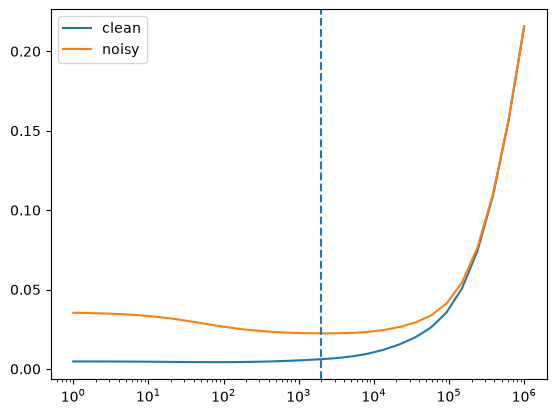

In [16]:
lams = np.logspace(0, 6, 30)

rmse_clean = []
rmse_noisy = []

for lam in lams:
    lhs = (np.transpose(firing_rates) @ firing_rates) + (lam * np.eye(50))
    rhs = (np.transpose(firing_rates) @ xs)

    decoder_reg = np.linalg.solve(lhs, rhs)

    # RMSE clean
    estimate_reg = firing_rates_100 @ decoder_reg
    error_reg = estimate_reg - xs_100
    sq_error_reg = error_reg**2
    mean_reg = np.mean(sq_error_reg)
    RMSE_reg = np.sqrt(mean_reg)
    rmse_clean.append(RMSE_reg)

    # RMSE noisy
    estimate_reg_noisy = noisy_frs @ decoder_reg
    error_reg_noisy = estimate_reg_noisy - xs_100
    sq_error_reg_noisy = error_reg_noisy**2
    mean_reg_noisy = np.mean(sq_error_reg_noisy)
    RMSE_reg_noisy = np.sqrt(mean_reg_noisy)
    rmse_noisy.append(RMSE_reg_noisy)

plt.plot(lams, rmse_clean, label="clean")
plt.plot(lams, rmse_noisy, label="noisy")
plt.xscale('log')
plt.axvline(2000, linestyle="dashed")
plt.legend()
plt.show()

As we can see, the formula was actually spot on! With that $\lambda$, the fit "knows" how noisy the test neurons will be.

The biological meaning is that an optimal readout is matched to the noise level of the population it reads from. Noisier inputs call for weights spread more evenly across many neurons; cleaner inputs allow finer, more precise weights.

Caveat: In NEF software (Nengo, which Spaun was built with), the noise level is usually not measured but set as an assumption: a fraction of the neurons’ maximum firing rate, typically around 10%.

## Populations representing vectors
Up to now x was a number, and each encoder was +1 or -1. Now x becomes a 2D vector ($x_1,x_2$). We can think of it as a movement direction on a table (ref. Georgopoulos motor cortex experiments).

The encoder becomes a preferred direction: a 2D arrow of length 1. Each neuron fires most when x points along its own arrow. 

The input current keeps the same form, but the product becomes a dot product!

$$
J = \text{gain} \times (\text{encoder} \cdot x - \text{intercept}) + 1 \\
\text{with encoder } \cdot x = e_1 \cdot x_1 + e_2 \cdot x_2
$$

We will draw a random angle for each neuron and turn each angle into an arrow of length 1:

Length encoder: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1.], of which every value is 1


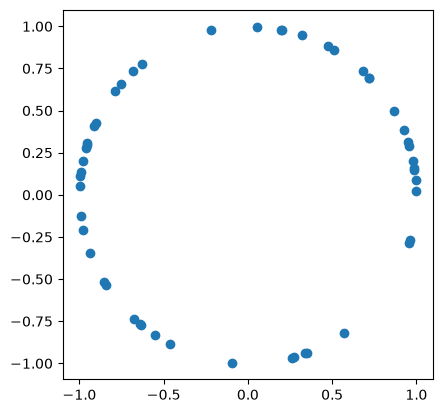

In [17]:
thetas = np.random.uniform(0, 2*np.pi, 50)

# Length of one is created using the formula of cos^2(x) + sin^2(x) = 1 (only possible in 2D, otherwise normalize vector by dividing by length)
# So we must take cos & sin of encoder angles
e1 = np.cos(thetas)
e2 = np.sin(thetas)

print(f"Length encoder: {np.sqrt(e1**2 + e2**2)}, of which every value is 1")

plt.scatter(e1, e2)
plt.gca().set_aspect('equal')

Let's put these encoders into a NeuronGroup!

In [18]:
import brian2 as b2
import numpy as np

b2.start_scope()

tau = 20*b2.ms
intercept = np.random.uniform(-1, 1, size=50) # value of (encoder · x) at which the neuron starts firing; sets its threshold in stimulus space
gain = np.random.uniform(1, 5, size=50)  # how steeply the firing rate rises once above the intercept; the slope of the f–I curve


eq = """
dv/dt = (I - v)/tau : 1 (unless refractory)
I = gain * ((e1 * x1 + e2 *x2) - intercept) + 1 : 1
gain : 1 (constant)
e1 : 1 (constant)
e2 : 1 (constant)
intercept : 1 (constant)
x1 : 1 (shared) # components of the stimulus vector being represented
x2 : 1 (shared) # components of the stimulus vector being represented
"""

G = b2.NeuronGroup(50, eq, threshold='v>1', reset = 'v=0', refractory=2*b2.ms)

G.intercept = intercept
G.e1, G.e2 = e1, e2 # components of the neuron's preferred direction (encoder), a unit vector
G.gain = gain

spmon = b2.SpikeMonitor(G) # Records the spikes

b2.store()

Now, we can measure the tuning curves in 2D. This is a computational version of Georgopoulos' center-out task: the monkey moves its arm in different directions while you record the motor cortex.

The stimuli are vectors of length 1 pointing in different directions around the circle. We again pick an angle, and give them length 1. 

Then, we loop over the angles and plot the tuning curves.

WARNING    'e1' is an internal variable of group 'neurongroup_1', but also exists in the run namespace with the value array([-0.95165789,  0.98874172, -0.99397182, ...,  0.95010672,
       -0.75489877,  0.27436515], shape=(50,)). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'intercept' is an internal variable of group 'neurongroup_1', but also exists in the run namespace with the value array([ 0.41216462, -0.8086407 , -0.4107899 , ...,  0.90297965,
        0.16995375,  0.71631949], shape=(50,)). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'e2' is an internal variable of group 'neurongroup_1', but also exists in the run namespace with the value array([ 0.30715999,  0.14963224,  0.10963583, ...,  0.31192502,
        0.65584132, -0.96162558], shape=(50,)). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'gain' is an int

(16, 50)


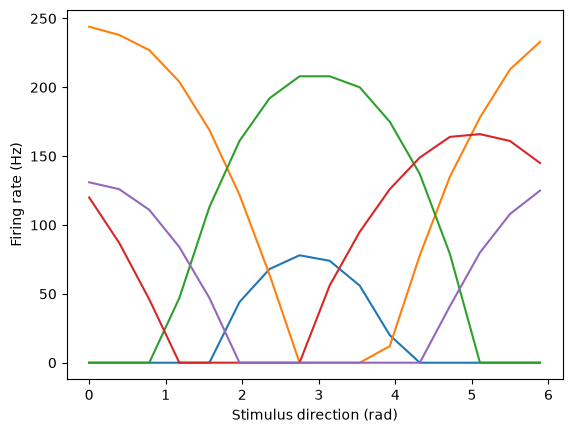

In [19]:
phis = np.linspace(0, 2*np.pi, 16, endpoint=False) # 0 & 2*pi are the same direction!

duration = 1*b2.second
firing_rates_2D = []

for phi in phis:
    b2.restore()
    G.x1 = np.cos(phi)
    G.x2 = np.sin(phi)
    b2.run(duration)
    firing_rates_2D.append((spmon.count/duration)/b2.Hz)

firing_rates_2D = np.array(firing_rates_2D)
print(firing_rates_2D.shape)

plt.plot(phis, firing_rates_2D[:, :5])
plt.xlabel("Stimulus direction (rad)")
plt.ylabel("Firing rate (Hz)")
plt.show()

These curves as sinusoid-like; Georgopoulos called this cosine tuning. Each neuron's input depends on $\text{encoder} \cdot x$. With both vectors of length 1, the dot product is exactly the cosine of the angle between them:
$$
\text{encoder} \cdot x = cos(\phi - \theta)
$$
- $\phi$ = stimulus direction
- $\theta$ = neuron's preferred direction

This means:
- The Peak at the preferred direction: When $\phi = \theta$, the cosine is 1 and the neuron fires most.
- Silent around the opposite direction: There the cosine is -1.

The intercept sets the width of each bump:
- High intercept: Fires only for directions close to the preferred one, giving a narrow bump.
- Negative intercept: Fires for most directions, giving a broad curve with only a short silent stretch. 
This is what M1 neurons do: $\text{Firing rate} \approx \text{baseline} + k \cdot cos(\text{movement direction - preferred direction})$. 

### Decoders for a 2D vector
The idea is the same as for our 1D approach, also the regularised equation stays the same (only with the target as a matrix with one column per component).

$$
(A^TA + \lambda I) D = A^TX
$$
- $A$ = firing rates (16x50)
- $X$ = the 16 stimulus vectors (16x2): column 1 is $cos(\phi)$, column 2 is $sin(\phi)$
- $I$ = the 50x50 identity matrix
- $D$ = the 50 decoders we're solving for
- $\lambda$ = the number of training trials $\times$ noise variance $= 16 \times 100 = 1600$

In [20]:
X = np.column_stack([np.cos(phis), np.sin(phis)])
lam = 1600

lhs = (np.transpose(firing_rates_2D) @ firing_rates_2D) + (lam * np.eye(50))
rhs = (np.transpose(firing_rates_2D) @ X)
decoder_2D = np.linalg.solve(lhs, rhs)
decoder_2D.shape

(50, 2)

The decoder now has shape (50, 2): One row per neuron, with two weights per row.

A row represents a 2D vector (the neuron's contribution to the estimate). The estimate of x is the sum over all neurons of (rate x decoder row):
$\hat{x} = d_1 \cdot rate_1 + d_2 \cdot rate_2 + … + d_{50} \cdot rate_{50}$ where each $d_i$ is now an arrow.

### Compare decoders with encoders
Are the optimised decoder arrows similar to the neuron's preferred directions?

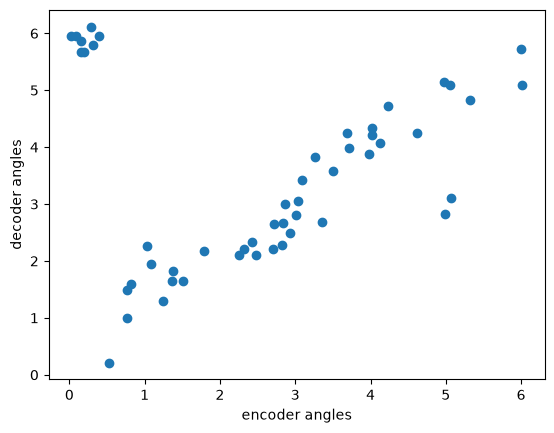

In [21]:
decoder_angles = np.arctan2(decoder_2D[:, 1], decoder_2D[:, 0]) # Reverse of cos/sin, the 2D-vector-to-angle function
decoder_angles = np.mod(decoder_angles, 2*np.pi)

plt.scatter(thetas, decoder_angles) # Encoder angles vs decoder angles
plt.xlabel("encoder angles")
plt.ylabel("decoder angles")
plt.show()

Except from some outliers, which may be a result of neurons with very small decoders.

The real test, however, is whether it recovers new stimuli.

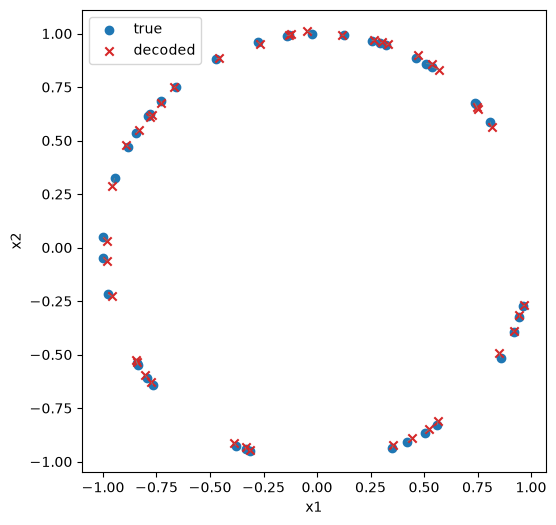

In [22]:
test_phis = np.random.uniform(0, 2*np.pi, 40) # New presented direction (theta is a neuron's preferred direction, it's encoder)

duration = 1*b2.second
test_firing_rates_2D = []

for phi in test_phis:
    b2.restore()
    G.x1 = np.cos(phi)
    G.x2 = np.sin(phi)
    b2.run(duration)
    test_firing_rates_2D.append((spmon.count/duration)/b2.Hz)

test_firing_rates_2D = np.array(test_firing_rates_2D)

result = test_firing_rates_2D @ decoder_2D # Column 0 is estimate of x1, column 1 of x2

true_x1 = np.cos(test_phis)
true_x2 = np.sin(test_phis)

plt.figure(figsize=(6, 6))

# Line from each true point to its decoded point
for i in range(len(test_phis)):
    plt.plot([true_x1[i], result[i, 0]],
             [true_x2[i], result[i, 1]],
             color='gray', linewidth=0.5)

plt.scatter(true_x1, true_x2, label='true', color='tab:blue')
plt.scatter(result[:, 0], result[:, 1], label='decoded',
            color='tab:red', marker='x')

plt.gca().set_aspect('equal')
plt.xlabel('x1')
plt.ylabel('x2')
plt.legend()
plt.show()


Encoders became random unit vectors (preferred directions $\theta$). Tuning curves against stimulus direction $\phi$ are rectified cosines, as in Georgopoulos’ center-out experiments. Regularised decoders ($50 \times 2, \lambda = 16 \times 100$) point roughly along each neuron’s preferred direction, with adjustments for uneven coverage and near-zero weights for rarely active neurons. Tested on 40 new random directions, the decoded vectors closely match the true ones, both in direction and length. Conclusion: the NEF scales from numbers to vectors by replacing $\text{encoder} \times x$ with the dot product $\text{encoder} \cdot x$.

### Adding noise
We can add noise as well:

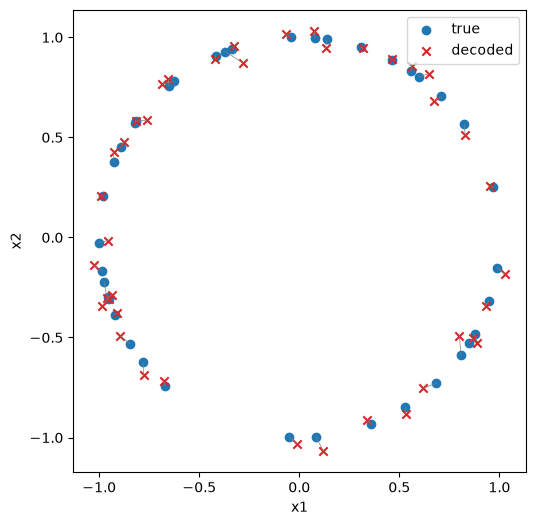

In [23]:
test_phis = np.random.uniform(0, 2*np.pi, 40) # New presented direction (theta is a neuron's preferred direction, it's encoder)

duration = 1*b2.second
test_firing_rates_2D = []

for phi in test_phis:
    b2.restore()
    G.x1 = np.cos(phi)
    G.x2 = np.sin(phi)
    b2.run(duration)
    test_firing_rates_2D.append((spmon.count/duration)/b2.Hz)

test_firing_rates_2D = np.array(test_firing_rates_2D)

# Independent noise (SD 10 Hz) to every neuron on every trial
noisy_test_rates_2D = test_firing_rates_2D + np.random.normal(0, 10, test_firing_rates_2D.shape)

result = noisy_test_rates_2D @ decoder_2D # Column 0 is estimate of x1, column 1 of x2

true_x1 = np.cos(test_phis)
true_x2 = np.sin(test_phis)

plt.figure(figsize=(6, 6))

# Line from each true point to its decoded point
for i in range(len(test_phis)):
    plt.plot([true_x1[i], result[i, 0]],
             [true_x2[i], result[i, 1]],
             color='gray', linewidth=0.5)

plt.scatter(true_x1, true_x2, label='true', color='tab:blue')
plt.scatter(result[:, 0], result[:, 1], label='decoded',
            color='tab:red', marker='x')

plt.gca().set_aspect('equal')
plt.xlabel('x1')
plt.ylabel('x2')
plt.legend()
plt.show()


As we can see, the red crosses scatter more because of the introduced random noise (affecting both direction & length). However, we still get good results and the representation survives.

## Create D-dimensional encoders
Here we increase the dimension of the vectors. However, when we do this we need to increase the amount of neurons as well.

We also want to have the vectors to have length 1, the reason differs per type of vector:
- Encoders: They say which direction a neuron prefers (how sensitive the neuron is, is the job of the gain). With every encoder at length 1, the drive measures only alignment (how much two vectors point the same way)
- Stimuli: Semantic pointers in Spaun have length 1. Keeping training stimuli at length 1 means the drive stays between -1 and +1 (if length would be 4, the drive would be between -4 & +4), the same range as the intercepts. So every neuron's threshold falls somewhere inside the range of drives it can actually experience. If the stimuli were much longer, almost every neuron would be either far above of below threshold.

In [24]:
D = 16
N = 400

# Create matrix (400 x 16): one row per neuron (encoders)
matrix = np.random.normal(0, 1, (N, D))
matrix.shape

# We want the encoder to describe only a direction (which pattern is preferred per neuron), so a length of 1 --> Normalize
encoders = matrix/np.linalg.norm(matrix, # Computing length of each row
                                 axis = 1, # Per row 
                                 keepdims = True) # Result keeps a shape that can divide the matrix

print(f"Length each encoder: {np.linalg.norm(encoders, axis = 1, keepdims = True)[:5]} ...")

Length each encoder: [[1.]
 [1.]
 [1.]
 [1.]
 [1.]] ...


### NeuronGroup for D dimensions
In 2D, the equation string had e1, e2 and x1, x2. With 16 dimensions that would mean 32 separate lines and this increases with more dimensions, hence we need a more efficient way of doing this. The idea is that each neuron needs one number, its drive: $encoder \cdot x$. The drive is the single number that tells a neuron how much the current stimulus "matches" it: $drive = encoder,\cdot x$. It is the input before gain & intercept are applied. It is the raw match; gain and intercept then turn it into a current. Biologically, it's the summed synaptic input from the stimulus: everything arriving at the neuron, collapsed into one number.

We can compute that for all neurons at once in numpy, as $encoders @ x$, and give each neuron its own value:
- Encoders is a (400x16) matrix: One row per neuron
- x is one 16D vector within this
- Encoders@x is taking the dot product of every row with x: $\text{drive of neuron i} = e_{i,1} \cdot x_{1} + e_{i,2} \cdot x_{2} + ... + e_{i,16} \cdot x_{16}$
- You get 400 dot products at once, one per neuron.

Example of 2D:
| Neuron | Encoder (preferred direction) | Stimulus x = (0.6, 0.8) | Drive = encoder · x | Meaning |
|---|---|---|---|---|
| 1 | (1, 0) | 1·0.6 + 0·0.8 | 0.60 | partly aligned |
| 2 | (0, 1) | 0·0.6 + 1·0.8 | 0.80 | well aligned |
| 3 | (0.6, 0.8) | 0.6·0.6 + 0.8·0.8 | 1.00 | same direction: fully aligned |
| 4 | (0.8, −0.6) | 0.8·0.6 + (−0.6)·0.8 | 0.00 | perpendicular: unrelated |
| 5 | (−0.6, −0.8) | −0.6·0.6 + (−0.8)·0.8 | −1.00 | opposite direction: anti-aligned |

All encoders and the stimulus have length 1, so each drive equals the cosine of the angle between the encoder and x, and always lies between −1 and +1.

Biologically, this corresponds to the summed synpatic input: the upstream population activity, weighted by this neuron's synapses, collapses into one input current. The neuron doesn't need to "known" the 16 components; it only feels the total.

In [25]:
import brian2 as b2
import numpy as np

b2.start_scope()

tau = 20*b2.ms
intercept = np.random.uniform(-1, 1, size=N) # value of (encoder · x) at which the neuron starts firing; sets its threshold in stimulus space
gain = np.random.uniform(1, 5, size=N)  # how steeply the firing rate rises once above the intercept; the slope of the f–I curve


eq = """
dv/dt = (I - v)/tau : 1 (unless refractory)
I = gain * (drive - intercept) + 1 : 1
gain : 1 (constant)
intercept : 1 (constant)
drive : 1
"""

G = b2.NeuronGroup(N, eq, threshold='v>1', reset = 'v=0', refractory=2*b2.ms)

G.intercept = intercept
G.gain = gain
# We assign drive in the trial loop: Each stimulus computes its own encoder@x

spmon = b2.SpikeMonitor(G) # Records the spikes

b2.store()

### Trial loop
The next step is to create a trial loop, where the stimuli become torchhd semantic pointers.

These stimuli represent random directions spread over the 16D sphere, the computational version of representing many random stimuli to map a neuron's response. Their purpose is to teach the decoders how to read out any vector the population might carry.

The decoders should work for any vector the population might have to carry: RED, CIRCLE, or the result of a binding we haven't computed yet. So we train on random directions everywhere, and test later on real semantic pointers. In other words, the concepts (RED, CIRCLE, ...) come only at test time. Because they were never in the training set, decoding them tests generalisation.

We save the firing rates, as each entry in the firing_rates_HD[t, i] is how strongly neuron i responds to stimulus t: How well that stimulus aligns with neuron i's preferred direction, passed through its intercept (threshold) and gain (slope). A whole row, all 400 rates in one trial, is the population's activity pattern for that stimulus. That pattern ís the neural representation of the 16D vector! Decoding is then the question of whether a weighted sum of that pattern recovers the original vector.

In [26]:
# Training stimuli: 200 random 16D unit vectors
n_train = 200
train_X = np.random.normal(0, 1, (n_train, D))
# Normalize (otherwise, drive is too strong and almost every neuron would be either far above or far below threshold)
train_X = train_X/np.linalg.norm(train_X, # Computing length of each row
                                 axis = 1, # Per row 
                                 keepdims = True) # Result keeps a shape that can divide the matrix


duration = 0.5*b2.second
firing_rates_HD = []

for x in train_X:
    b2.restore()
    G.drive = encoders @ x # 400 values, one per neuron
    b2.run(duration)
    firing_rates_HD.append((spmon.count/duration)/b2.Hz)

firing_rates_HD = np.array(firing_rates_HD)
print(f"Here we want {n_train} trials x {N} neurons: {firing_rates_HD.shape}")

WARNING    'intercept' is an internal variable of group 'neurongroup', but also exists in the run namespace with the value array([ 0.21149031, -0.51168312, -0.88488101, ...,  0.7301071 ,
       -0.50829436,  0.95106654], shape=(400,)). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'gain' is an internal variable of group 'neurongroup', but also exists in the run namespace with the value array([2.67535116, 2.74980566, 2.82469184, ..., 4.68019692, 3.53936563,
       4.5173572 ], shape=(400,)). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
INFO       No numerical integration method specified for group 'neurongroup', using method 'exact' (took 0.02s). [brian2.stateupdaters.base.method_choice]


Here we want 200 trials x 400 neurons: (200, 400)


### Decoders for 16D
For the decoders, we use the same recipe we've been using, just larger. Each neuron now needs 16 weights, one per dimension, so the encoders form a (400 x 16) matrix.

$(A^TA + \lambda I) D = A^T X$
- $A$ = firing_rates_HD (200 x 400)
- $X$ = train_X (200 x 16), the stimulus vectors themselves, so no column_stack is needed here
- $I$ = identity matrix (400 x 400) for 400 neurons
- $\lambda$ = number of training trails x noise variance = $200 \times 100 = 20,000$
  - We choose the noise ourselves: Assuming noise with an SD of 10 Hz, the variance is $10^2 = 100$, about 5% of a maximum rate of around 200 Hz.
  - When we test, we will add exactly that 10 Hz noise, so the decoders are matched to it. 
  - We could choose noisier neurons, say SD 20 Hz, $\lambda$ becomes $200 \times 400 = 80,000$
  - In a real experiment you would measure the variance from repeated presentations of the same stimulus. In Nengo, it's set as an assumption: a fraction of the maximum firing rate.

In [27]:
lam = 20000

lhs = (np.transpose(firing_rates_HD) @ firing_rates_HD) + (lam * np.eye(N))
rhs = (np.transpose(firing_rates_HD) @ train_X)
decoder_HD = np.linalg.solve(lhs, rhs)
decoder_HD.shape

(400, 16)

The decoder_HD variable now means: Each row is a 16D arrow, that neuron's contribution to the decoded vector. A neuron that fires strongly pushes the estimate along its arrow.

### Decode semantic pointers
Now we will create neurons that represent actual concepts.
1. Vocabulary (D = 16)
2. Convert & normalize (brian2 needs numpy arrays)
3. Present each concept to the population
4. Decode
5. Compare

In [28]:
# 1. Vocabulary
vocab = ["COLOR", "SHAPE", "RED", "BLUE", "CIRCLE", "SQUARE"]
hvs = torchhd.random(len(vocab), D, vsa="HRR")
vocab_hv = dict(zip(vocab, hvs))

# 2. Convert & normalize
for v in vocab_hv:
    # Convert
    vocab_hv[v] = vocab_hv[v].numpy()
    # Normalize
    vocab_hv[v] = vocab_hv[v]/np.linalg.norm(vocab_hv[v]) # No axis = 1, because a 1D vector has only one axis

print(f"Length each vocabulary vector: {np.linalg.norm(vocab_hv["RED"])}")

# 3. Present each concept to the population: Same loop as training data, but over vocab vectors
vocab_rates = []

for v in vocab_hv:
    b2.restore()
    G.drive = encoders @ vocab_hv[v] # 400 values, one per neuron
    b2.run(duration)
    vocab_rates.append((spmon.count/duration)/b2.Hz)

vocab_rates = np.array(vocab_rates)
print(f"Here we want {len(vocab)} trials x {N} neurons: {vocab_rates.shape}")

# 4. Decode
result = vocab_rates @ decoder_HD # One decoded 16D vector per concept (6 x 16)
print(f"Shape of result: {result.shape}")

# 5. Compare (You could use torchhd again, but that would require conversion again!)
sims = np.zeros((len(vocab), len(vocab)))   # empty 6 x 6 table

for i, r in enumerate(result): # i = row number, r = decoded vector
    for j, v in enumerate(vocab): # j = column vector, v = vocabulary name
        # Cosine similarity
        sims[i,j] = np.dot(r, vocab_hv[v])/(np.linalg.norm(r) * np.linalg.norm(vocab_hv[v]))
        
table = pd.DataFrame(sims, index = vocab, columns = vocab).round(2)
print(table)

Length each vocabulary vector: 1.0
Here we want 6 trials x 400 neurons: (6, 400)
Shape of result: (6, 16)
        COLOR  SHAPE   RED  BLUE  CIRCLE  SQUARE
COLOR    1.00   0.05 -0.44  0.26    0.13    0.00
SHAPE    0.00   1.00 -0.31  0.23    0.14    0.04
RED     -0.49  -0.31  1.00 -0.14   -0.40    0.21
BLUE     0.24   0.22 -0.13  1.00   -0.17    0.04
CIRCLE   0.14   0.14 -0.38 -0.15    1.00   -0.12
SQUARE   0.03   0.07  0.19  0.07   -0.11    1.00


Every concept is decoded correctly, the diagonal is 1.00 in every row. Again, this is without noise!

However, some off-diagonal values are quite high (SHAPE vs RED = 0.48, COLOR vs SHAPE = -0.36). Also, they are almost symmetric: SHAPE-RED is 0.48 and RED-SHAPE is 0.47; COLOR-BLUE is 0.31 and BLUE-COLOR is 0.31. These are not decoding errors. 

This suggests these values come from the vocabulary itself, not from the neurons. The random vectors SHAPE & RED happen to be fairly similar to each other. By increasing the dimensions, we can lower these random similarities.

We can check where the off-diagonal values come from by comparing the vocabulary vectors with each other instead of decoded vectors with vocabulary vectors:

In [29]:
comp_vocab = np.zeros((len(vocab), len(vocab)))   # empty 6 x 6 table

for i, v1 in enumerate(vocab): # i = row number, r = decoded vector
    for j, v2 in enumerate(vocab): # j = column vector, v = vocabulary name
        # Cosine similarity
        comp_vocab[i,j] = np.dot(vocab_hv[v1], vocab_hv[v2])/(np.linalg.norm(vocab_hv[v1]) * np.linalg.norm(vocab_hv[v2]))
        
table = pd.DataFrame(comp_vocab, index = vocab, columns = vocab).round(2)
print(table)

        COLOR  SHAPE   RED  BLUE  CIRCLE  SQUARE
COLOR    1.00   0.05 -0.46  0.24    0.13    0.00
SHAPE    0.05   1.00 -0.31  0.23    0.13    0.04
RED     -0.46  -0.31  1.00 -0.14   -0.39    0.19
BLUE     0.24   0.23 -0.14  1.00   -0.17    0.03
CIRCLE   0.13   0.13 -0.39 -0.17    1.00   -0.11
SQUARE   0.00   0.04  0.19  0.03   -0.11    1.00


We can see that the two tables have very similar data, so that confirms that it comes from the vocabulary itself and that they are not decoding errors! The real limit is the dimensionality.

### Adding noise
We can add noise to vocab_rates and rebuild the table.

In [30]:
# 1. Vocabulary: Done earlier
# 2. Convert & normalize: Done earlier

# 3. Present each concept to the population: Same loop as training data, but over vocab vectors
vocab_rates = []

for v in vocab_hv:
    b2.restore()
    G.drive = encoders @ vocab_hv[v] # 400 values, one per neuron
    b2.run(duration)
    vocab_rates.append((spmon.count/duration)/b2.Hz)

# Here we add noise!
vocab_rates = np.array(vocab_rates)
vocab_rates_noisy = vocab_rates + np.random.normal(0, 10, vocab_rates.shape)
print(f"Here we want {len(vocab)} trials x {N} neurons: {vocab_rates_noisy.shape}")

# 4. Decode
result = vocab_rates_noisy @ decoder_HD # One decoded 16D vector per concept (6 x 16)
print(f"Shape of result: {result.shape}")

# 5. Compare (You could use torchhd again, but that would require conversion again!)
sims = np.zeros((len(vocab), len(vocab)))   # empty 6 x 6 table

for i, r in enumerate(result): # i = row number, r = decoded vector
    for j, v in enumerate(vocab): # j = column vector, v = vocabulary name
        # Cosine similarity
        sims[i,j] = np.dot(r, vocab_hv[v])/(np.linalg.norm(r) * np.linalg.norm(vocab_hv[v]))
        
table = pd.DataFrame(sims, index = vocab, columns = vocab).round(2)
print(table)

Here we want 6 trials x 400 neurons: (6, 400)
Shape of result: (6, 16)
        COLOR  SHAPE   RED  BLUE  CIRCLE  SQUARE
COLOR    1.00   0.05 -0.46  0.27    0.11   -0.01
SHAPE    0.04   0.99 -0.37  0.20    0.22    0.03
RED     -0.49  -0.33  0.99 -0.12   -0.36    0.17
BLUE     0.28   0.26 -0.19  1.00   -0.11    0.01
CIRCLE   0.21   0.15 -0.40 -0.09    0.99   -0.14
SQUARE   0.01   0.08  0.22  0.07   -0.11    0.99


As expected, the noise creates uncertainty even on the diagonal. However, the diagonal is still the largest in every row. This robustness comes from 400 neurons that share the work and the decoders that are regularized for exactly this noise level.

## Present a scene to the population

In [31]:
# Helper: numpy array -> torchhd HRR vector
def to_hrr(array):
    return torchhd.HRRTensor(torch.tensor(array, dtype = torch.float32))

# 1. Bind: attach each filler to its role
RedxColor = torchhd.bind(to_hrr(vocab_hv["RED"]), to_hrr(vocab_hv["COLOR"]))
CirclexShape = torchhd.bind(to_hrr(vocab_hv["CIRCLE"]), to_hrr(vocab_hv["SHAPE"]))

# 2. Bundle: both facts in one scene vector
scene = torchhd.bundle(RedxColor, CirclexShape)

# 3. Convert & normalize the scene
scene = scene.numpy()
scene = scene/np.linalg.norm(scene) # Length 1, like all our stimuli

# 4. Present the scene to the population (one trial)
b2.restore()
G.drive = encoders @ scene # 400 values, one per neuron
b2.run(duration)
scene_rates = (spmon.count/duration)/b2.Hz

# Add noise (same 10 Hz as before)
scene_rates_noisy = scene_rates + np.random.normal(0, 10, scene_rates.shape)

# 5. Decode: the population's version of the scene
decoded_scene = scene_rates_noisy @ decoder_HD # One 16D vector

# 6. Unbind COLOR from the decoded scene: "what is the COLOR?"
query = torchhd.bind(to_hrr(decoded_scene), torchhd.inverse(to_hrr(vocab_hv["COLOR"])))
query = query.numpy()

# 7. Compare with every vocabulary vector
for v in vocab:
    sim = np.dot(query, vocab_hv[v])/(np.linalg.norm(query) * np.linalg.norm(vocab_hv[v]))
    print(f"query vs {v}: {sim:.2f}")

query vs COLOR: -0.53
query vs SHAPE: -0.08
query vs RED: 0.75
query vs BLUE: -0.12
query vs CIRCLE: -0.39
query vs SQUARE: 0.26


We can check whether the neurons change the scene

We unbind COLOR from the **original scene** (before it went through the neurons) and compare it with the unbinding of the **decoded scene** (after the neurons).

- If both give almost the same similarities, the population carried the scene faithfully, and any thin margins come from the low dimensionality (D = 16), not from the neurons.
- If the decoded version is clearly worse, the neurons (or the noise) are losing information.

In [32]:
# Unbind COLOR from the ORIGINAL scene (no neurons involved)
query_original = torchhd.bind(to_hrr(scene), torchhd.inverse(to_hrr(vocab_hv["COLOR"])))
query_original = query_original.numpy()

# Compare both queries with every vocabulary vector
sims_original = []
sims_decoded = []

for v in vocab:
    sim_o = np.dot(query_original, vocab_hv[v])/(np.linalg.norm(query_original) * np.linalg.norm(vocab_hv[v]))
    sim_d = np.dot(query, vocab_hv[v])/(np.linalg.norm(query) * np.linalg.norm(vocab_hv[v]))
    sims_original.append(sim_o)
    sims_decoded.append(sim_d)

# Side-by-side table
table = pd.DataFrame({"original scene": sims_original,
                      "decoded scene": sims_decoded},
                     index = vocab).round(2)
print(table)

        original scene  decoded scene
COLOR            -0.55          -0.53
SHAPE            -0.10          -0.08
RED               0.76           0.75
BLUE             -0.12          -0.12
CIRCLE           -0.39          -0.39
SQUARE            0.25           0.26


The scene $COLOR \otimes RED + SHAPE \otimes CIRCLE$ (torchhd, D = 16) was presented to the 400-neuron population, decoded from noisy rates, and then unbound with $COLOR^{-1}$. $RED$ came out on top (0.63), nearly identical to unbinding the original scene without neurons (0.64). The other similarities also match closely. 

So, the population carries a structured scene without losing its internal structure; the thin margin to $CIRCLE$ (0.56) is caused by unbinding noise and the low dimensionality, not by the neurons.

### Visualizations
**Caveat**: While I try to write everything on my own, with guidelines from Claude, the visualizations are completely copy-paste and should be interpreted with caution.


#### Activity maps: Which neurons light up for each concept
This is like calcium imaging: a field of neurons, with brightness showing activity. We arrange the 400 neurons as a 20 × 20 grid. The positions are arbitrary, since our neurons have no spatial layout, but it makes the activity pattern visible.

Each concept activates a different pattern across the same 400 neurons. No neuron is “the RED neuron”; RED is the pattern. Concepts that are similar in the vocabulary (like RED and CIRCLE) should have patterns that look somewhat alike. That’s the population code from the earlier diagram, made visible.

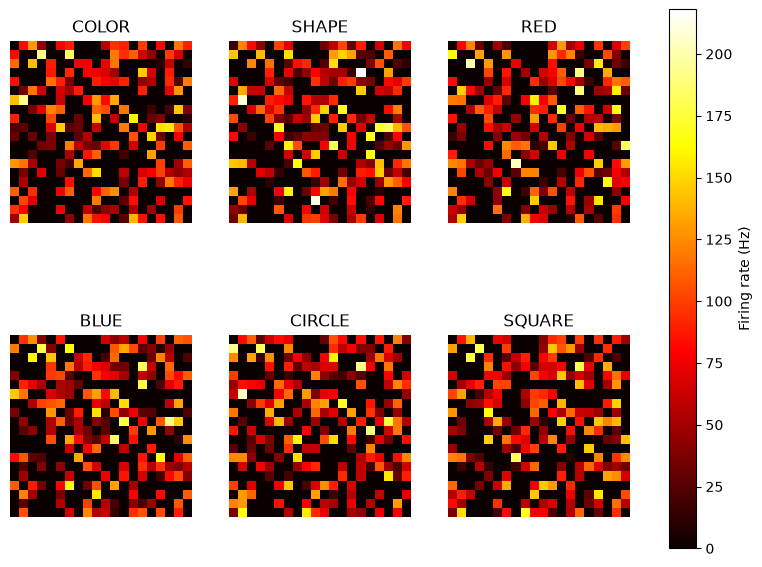

In [33]:
fig, axes = plt.subplots(2, 3, figsize=(10, 7))

for i, v in enumerate(vocab):
    ax = axes.flat[i]
    activity = vocab_rates[i].reshape(20, 20)   # 400 neurons -> 20 x 20 grid
    im = ax.imshow(activity, cmap='hot', vmin=0, vmax=vocab_rates.max())
    ax.set_title(v)
    ax.axis('off')

fig.colorbar(im, ax=axes, label='Firing rate (Hz)')
plt.show()

#### Activity maps, but nicer...
**What the plot shows.** Each circle is one of the 400 LIF neurons in the population. The colour shows its firing rate while one stimulus is presented: white = silent, darker red = faster firing. Click a button on the left to present a different stimulus; hover over a neuron to see its number and firing rate.

**How to read it.**
- The positions are arbitrary (a jittered 20 × 20 grid): our neurons have no real spatial layout. They are the same for every stimulus, so the same circle is always the same neuron.
- No single neuron codes for a concept. Each concept is a **pattern of activity** across the whole population, and each neuron responds to several concepts (mixed selectivity).
- Many neurons stay silent for a given stimulus (sparse activity): in 16 dimensions, a random stimulus is only weakly aligned with most neurons' preferred directions.

**Pattern similarity.** For the combinations, the title shows the correlation between the stimulus's activity pattern and the patterns of its parts (1 = identical patterns, around 0 = unrelated). This is the same kind of comparison as in representational similarity analysis (RSA).

**What it demonstrates.**
- **Binding** (RED ⊛ COLOR, CIRCLE ⊛ SHAPE) produces a **new** activity pattern with low similarity to its parts, like conjunctive coding.
- **Bundling** (the scene = RED ⊛ COLOR + CIRCLE ⊛ SHAPE) keeps **high** similarity with what was bundled, so both bound pairs remain recognisable in the scene's activity.
- The concepts inside the bindings (RED, CIRCLE…) are hidden in the scene's activity, but can still be recovered by unbinding the decoded scene, as shown in the previous step.

**Caveats.** The firing rates are noise-free (deterministic LIF neurons), and the dimensionality is low (D = 16), so some unrelated concepts already have fairly similar patterns by chance.

In [40]:
# --- 1. Stimuli: 6 concepts + combinations ---
stimuli = {}
for v in vocab:
    stimuli[v] = vocab_hv[v]

RedxColor_np = RedxColor.numpy()
CirclexShape_np = CirclexShape.numpy()
stimuli["RED ⊛ COLOR"] = RedxColor_np/np.linalg.norm(RedxColor_np)
stimuli["CIRCLE ⊛ SHAPE"] = CirclexShape_np/np.linalg.norm(CirclexShape_np)
stimuli["Scene"] = scene

# --- 2. Present each stimulus once and store the rates ---
def present(x):
    b2.restore()
    G.drive = encoders @ x # 400 values, one per neuron
    b2.run(duration)
    return (spmon.count/duration)/b2.Hz

stim_rates = {}
for s in stimuli:
    stim_rates[s] = present(stimuli[s])

# --- 3. Neuron positions (20 x 20 grid, slightly jittered) and colour scale ---
rng = np.random.default_rng(0)
gx, gy = np.meshgrid(np.arange(20), np.arange(20))
pos = np.column_stack([gx.ravel(), gy.ravel()]).astype(float)
pos += rng.uniform(-0.25, 0.25, pos.shape)

vmax = max(stim_rates[s].max() for s in stim_rates) # Same colour scale for every stimulus

In [42]:
import plotly.graph_objects as go

# If the bundle was added in an earlier cell, remove it so it doesn't show up
stim_rates.pop("BUNDLE: RED + CIRCLE", None)

# Pattern similarity: correlation between two activity patterns across all neurons 
all_rates = np.array([stim_rates[s] for s in stim_rates]) # (stimuli x neurons)
neuron_means = all_rates.mean(axis=0)                     # each neuron's average rate

def pattern_sim(rates_a, rates_b):
    return np.corrcoef(rates_a - neuron_means, rates_b - neuron_means)[0, 1] # We remove the neuron's baseline before correlating (taken from RSA, Kriegeskorte et al. 2008)

# What each combination is made of
parts = {
    "RED ⊛ COLOR": ["RED", "COLOR"],
    "CIRCLE ⊛ SHAPE": ["CIRCLE", "SHAPE"],
    "Scene": ["RED ⊛ COLOR", "CIRCLE ⊛ SHAPE"],
}

def make_title(s):
    rates = stim_rates[s]
    title = f"{s}: {np.sum(rates > 0)} of {N} neurons active"
    if s in parts:
        sims = [f"{p}: {pattern_sim(rates, stim_rates[p]):.2f}" for p in parts[s]]
        title += "<br><sup>Pattern similarity with its parts: " + " | ".join(sims) + "</sup>"
    return title

names = list(stim_rates.keys())

# One scatter plot of the 400 neurons, coloured by the first stimulus
fig = go.Figure(go.Scatter(
    x=pos[:, 0], y=pos[:, 1], mode='markers',
    marker=dict(size=14, color=stim_rates[names[0]],
                colorscale='Reds', cmin=0, cmax=vmax,
                line=dict(color='#999999', width=0.6),
                colorbar=dict(title='Hz')),
    text=[f"Neuron {i}" for i in range(N)],
    hovertemplate="%{text}<br>%{marker.color:.0f} Hz<extra></extra>"))

# One button per stimulus: clicking it swaps the colours and the title
buttons = []
for s in names:
    buttons.append(dict(
        label=s, method='update',
        args=[{'marker.color': [stim_rates[s]]},
              {'title': make_title(s)}]))

fig.update_layout(
    updatemenus=[dict(type='buttons', direction='down', buttons=buttons,
                      x=-0.05, xanchor='right', y=1, yanchor='top')],
    title=make_title(names[0]),
    width=750, height=680, plot_bgcolor='white',
    xaxis=dict(visible=False), yaxis=dict(visible=False, scaleanchor='x'),
    margin=dict(l=160, t=100))

fig.show()

#### Spike raster: The spikes behind one concept
This is like multi-electrode recording: every row is one neuron, and every dot one spike. We present one concept and sort the neurons by their drive, so the neurons best aligned with the concept sit at the top.

A silent band at the bottom (neurons that “dislike” RED, drive below their intercept), then neurons firing increasingly fast towards the top. Each row is a perfectly regular spike train, because our LIF neurons are deterministic. Real cortical neurons would look far more irregular, which is what the added noise stands in for.

WARNING    'drive' is an internal variable of group 'neurongroup', but also exists in the run namespace with the value array([-0.2234335 ,  0.02715151,  0.10129833, ..., -0.18659132,
        0.01082747,  0.12784414], shape=(400,)). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


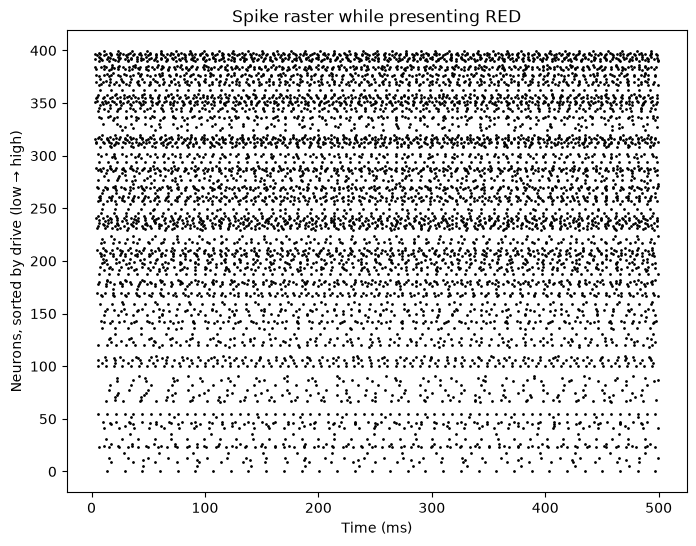

In [35]:
concept = "RED"

# Present the concept and record spikes
b2.restore()
drive = encoders @ vocab_hv[concept]
G.drive = drive
b2.run(duration)

# Sort neurons by drive: best-aligned neurons at the top
order = np.argsort(drive)            # lowest drive first
rank = np.zeros(N, dtype=int)
rank[order] = np.arange(N)           # rank[neuron] = its position in the sorted list

plt.figure(figsize=(8, 6))
plt.scatter(spmon.t/b2.ms, rank[spmon.i], s=1, color='black')
plt.xlabel('Time (ms)')
plt.ylabel('Neurons, sorted by drive (low → high)')
plt.title(f'Spike raster while presenting {concept}')
plt.show()

### Tuning to concepts: What each neuron prefers
This is like a selectivity matrix from single-unit recordings: rows are neurons, columns are concepts, and colour is the rate. We sort the neurons by which concept drives them most.

Blocks of neurons that prefer each concept, but almost every neuron also responds to several concepts. That’s mixed selectivity: neurons aren’t labelled lines for single concepts. It’s the same picture you see in recordings from prefrontal cortex.

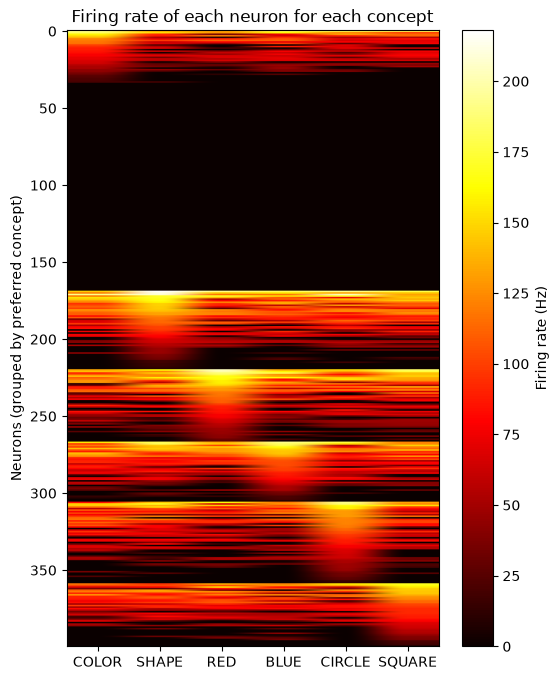

In [36]:
preferred = np.argmax(vocab_rates, axis=0)          # each neuron's favourite concept
order = np.lexsort((-vocab_rates.max(axis=0), preferred))   # group by favourite, strongest first

plt.figure(figsize=(6, 8))
plt.imshow(vocab_rates[:, order].T, aspect='auto', cmap='hot')
plt.xticks(range(len(vocab)), vocab)
plt.ylabel('Neurons (grouped by preferred concept)')
plt.colorbar(label='Firing rate (Hz)')
plt.title('Firing rate of each neuron for each concept')
plt.show()